In [6]:
import gymnasium as gym
import numpy as np
import random
from collections import deque, namedtuple
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import optuna
from IPython.display import clear_output, display

In [2]:
# Создание и исследование среды Lunalander с дискретным пространством действий
env = gym.make("LunarLander-v3")
print(f"Пространство действий: {env.action_space}")
print(f"Пространство наблюдений: {env.observation_space}")
    
# Сброс среды и случайный шаг
obs, info = env.reset(seed=42)
print(f"Пример наблюдения: {obs}")
    
# Запуск случайной политики
print(f"Случайная политика:")
total_rewards = []
for ep in range(5):
    obs, _ = env.reset()
    done = False
    total = 0
    while not done:
        action = env.action_space.sample()
        obs, reward, terminated, truncated, _ = env.step(action)
        total += reward
        done = terminated or truncated
    total_rewards.append(total)
    print(f"Эпизод {ep+1}: награда = {total:.2f}")
print(f"Средняя награда: {np.mean(total_rewards):.2f}")
    
env.close()

Пространство действий: Discrete(4)
Пространство наблюдений: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Пример наблюдения: [ 0.00229702  1.4181306   0.2326471   0.3204666  -0.00265488 -0.05269805
  0.          0.        ]
Случайная политика:
Эпизод 1: награда = -289.79
Эпизод 2: награда = -202.12
Эпизод 3: награда = 81.64
Эпизод 4: награда = -386.31
Эпизод 5: награда = -354.38
Средняя награда: -230.19


In [3]:
Transition = namedtuple("Transition", ["state", "action", "reward", "next_state", "done"])

class ReplayBuffer:
    # Буфер воспроизведения опыта    
    def __init__(self, capacity=100_000):
        self.buffer = deque(maxlen=capacity)
    
    def push(self, *args):
        self.buffer.append(Transition(*args))
    
    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        return Transition(*zip(*batch))
    
    def __len__(self):
        return len(self.buffer)

class QNetwork(nn.Module):
    # Аппроксимация Q-функции
    def __init__(self, obs_dim, n_actions, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )
    
    def forward(self, x):
        return self.net(x)

class DQNAgent:
    def __init__(
        self,
        obs_dim: int,
        n_actions: int,
        lr: float = 1e-3,
        gamma: float = 0.99,
        tau: float = 0.005,
        buffer_size: int = 100_000,
        batch_size: int = 64,
        eps_start: float = 1.0,
        eps_end: float = 0.05,
        eps_decay: float = 0.995,
        device: str = "cuda",
    ):
        self.n_actions = n_actions
        self.gamma = gamma
        self.tau = tau
        self.batch_size = batch_size
        self.device = torch.device(device)
        
        self.q_net = QNetwork(obs_dim, n_actions).to(self.device)
        self.target_net = QNetwork(obs_dim, n_actions).to(self.device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        
        self.optimizer = optim.Adam(self.q_net.parameters(), lr=lr)
        self.buffer = ReplayBuffer(buffer_size)
        
        # Эпсилон-жадный алгоритм
        self.epsilon = eps_start
        self.eps_end = eps_end
        self.eps_decay = eps_decay
    
    def select_action(self, state, eval_mode=False):
        if not eval_mode and random.random() < self.epsilon:
            return random.randrange(self.n_actions)
        with torch.no_grad():
            state_t = torch.as_tensor(state, dtype=torch.float32, 
                                      device=self.device).unsqueeze(0)
            q_values = self.q_net(state_t)
            return int(q_values.argmax(dim=1).item())
    
    def soft_update(self):
        # Мягкое обновление целевой сети
        with torch.no_grad():
            for tp, p in zip(self.target_net.parameters(), self.q_net.parameters()):
                tp.data.mul_(1.0 - self.tau)
                tp.data.add_(self.tau * p.data)
       
    def train_step(self):
        if len(self.buffer) < self.batch_size:
            return None
      
        batch = self.buffer.sample(self.batch_size)
        
        states = torch.as_tensor(np.array(batch.state), dtype=torch.float32, device=self.device)
        actions = torch.as_tensor(batch.action, dtype=torch.long, device=self.device).unsqueeze(1)
        rewards = torch.as_tensor(batch.reward, dtype=torch.float32, device=self.device).unsqueeze(1)
        next_states = torch.as_tensor(np.array(batch.next_state), dtype=torch.float32, device=self.device)
        dones = torch.as_tensor(batch.done, dtype=torch.float32, device=self.device).unsqueeze(1)
        
        q_values = self.q_net(states).gather(1, actions)
        
        with torch.no_grad():
            next_q = self.target_net(next_states).max(dim=1, keepdim=True)[0]
            target = rewards + self.gamma * next_q * (1.0 - dones)
        
        loss = F.mse_loss(q_values, target)
        
        self.optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(self.q_net.parameters(), max_norm=10.0)
        self.optimizer.step()
        
        # Мягкое обновление целевой сети на каждом шаге обучения
        self.soft_update()
        
        # Затухание значения эпсилон
        self.epsilon = max(self.eps_end, self.epsilon * self.eps_decay)
        
        return loss.item()

In [9]:
def moving_average(x, window=100):
    x = np.asarray(x, dtype=np.float32)
    if len(x) < window:
        return np.array([])
    kernel = np.ones(window, dtype=np.float32) / window
    return np.convolve(x, kernel, mode="valid")

def train(env_id="LunarLander-v3", n_episodes=1000, seed=42,
          plot_every=20, log_every=20, live_plot=True, agent_kwargs=None):
    env = gym.make(env_id)
    obs_dim = env.observation_space.shape[0]
    n_actions = env.action_space.n

    default_kwargs = dict(
        lr=1e-3, gamma=0.99, tau=0.005,
        buffer_size=100_000, batch_size=64,
        eps_start=1.0, eps_end=0.05, eps_decay=0.995,
    )
    if agent_kwargs:
        default_kwargs.update(agent_kwargs)

    agent = DQNAgent(
        obs_dim=obs_dim, n_actions=n_actions,
        device="cuda" if torch.cuda.is_available() else "cpu",
        **default_kwargs,
    )

    episode_rewards = []
    log_lines = []

    if live_plot:
        fig, ax = plt.subplots(figsize=(10, 4))

    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done = False
        total_reward = 0.0

        while not done:
            action = agent.select_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            agent.buffer.push(state, action, reward, next_state, float(done))
            agent.train_step()

            state = next_state
            total_reward += reward

        episode_rewards.append(total_reward)

        if (ep + 1) % log_every == 0:
            avg100 = np.mean(episode_rewards[-100:])
            log_lines.append(
                f"Эпизод {ep+1:4d} | награда={total_reward:7.1f} | "
                f"Средняя(100)={avg100:7.1f} | ε={agent.epsilon:.3f}"
            )
            if not live_plot:
                print(log_lines[-1])

        if live_plot and (ep + 1) % plot_every == 0:
            clear_output(wait=True)
            for line in log_lines:
                print(line)

            ax.clear()
            ax.plot(episode_rewards, alpha=0.25, color="tab:blue", label="награда за эпизод")
            avg = moving_average(episode_rewards, 100)
            if len(avg):
                xs = np.arange(99, 99 + len(avg))
                ax.plot(xs, avg, color="tab:orange", linewidth=2, label="средняя за 100")
            ax.axhline(200, color="red", linestyle="--", label="порог решения (200)")
            ax.set_xlabel("эпизод"); ax.set_ylabel("награда")
            ax.set_title(f"{env_id} - обучение DQN")
            ax.legend(loc="upper left"); ax.grid(alpha=0.3)
            display(fig)

        if len(episode_rewards) >= 100 and np.mean(episode_rewards[-100:]) >= 200:
            print(f"Решено на эпизоде {ep+1} | Средняя за 100: {np.mean(episode_rewards[-100:]):.1f}")
            break

    env.close()

    return agent, episode_rewards

Эпизод   20 | награда=  -84.9 | Средняя(100)= -167.8 | ε=0.050
Эпизод   40 | награда=  -96.6 | Средняя(100)= -122.2 | ε=0.050
Эпизод   60 | награда=  -97.4 | Средняя(100)=  -96.9 | ε=0.050
Эпизод   80 | награда=   18.0 | Средняя(100)=  -81.0 | ε=0.050
Эпизод  100 | награда=  -62.7 | Средняя(100)=  -81.4 | ε=0.050
Эпизод  120 | награда=  244.6 | Средняя(100)=  -38.9 | ε=0.050
Эпизод  140 | награда=  190.6 | Средняя(100)=   -5.1 | ε=0.050
Эпизод  160 | награда=  205.7 | Средняя(100)=   15.5 | ε=0.050
Эпизод  180 | награда=  246.1 | Средняя(100)=   21.9 | ε=0.050
Эпизод  200 | награда=    4.5 | Средняя(100)=   57.5 | ε=0.050
Эпизод  220 | награда=   76.4 | Средняя(100)=   91.1 | ε=0.050
Эпизод  240 | награда=  247.3 | Средняя(100)=  111.8 | ε=0.050
Эпизод  260 | награда=  246.3 | Средняя(100)=  141.6 | ε=0.050
Эпизод  280 | награда=   -6.7 | Средняя(100)=  184.1 | ε=0.050
Эпизод  300 | награда=   16.5 | Средняя(100)=  191.8 | ε=0.050
Эпизод  320 | награда=  220.7 | Средняя(100)=  174.2 | 

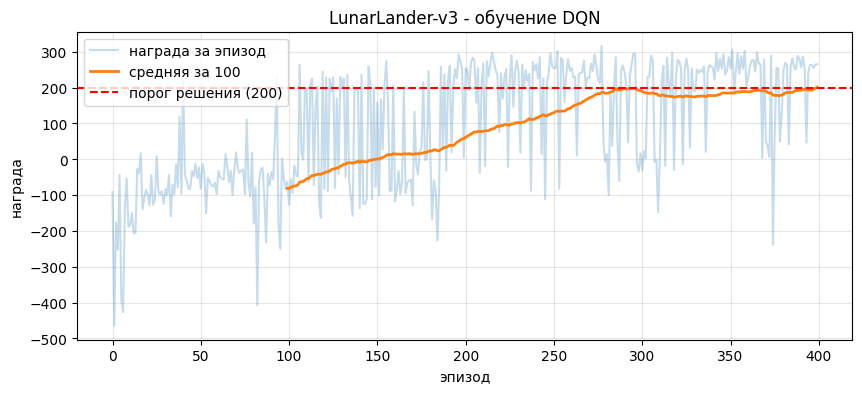

Решено на эпизоде 400 | Средняя за 100: 200.7


In [10]:
agent, rewards = train(
    env_id="LunarLander-v3",
    n_episodes=1000,
    plot_every=20,
    live_plot=True
)

Оптимизация гиперпараметров с помощью Optuna

In [6]:
def objective(trial):
    kwargs = {
        "lr":        trial.suggest_float("lr", 1e-4, 5e-3, log=True),
        "gamma":     trial.suggest_float("gamma", 0.95, 0.999),
        "tau":       trial.suggest_float("tau", 0.001, 0.05, log=True),
        "batch_size": trial.suggest_categorical("batch_size", [32, 64, 128]),
        "eps_decay": trial.suggest_float("eps_decay", 0.99, 0.999),
    }

    _, rewards = train(
        env_id="LunarLander-v3",
        n_episodes=200,
        log_every=50,
        live_plot=False,
        agent_kwargs=kwargs,
    )

    if len(rewards) == 0:
        raise optuna.TrialPruned()

    for k in range(50, len(rewards) + 1, 50):
        trial.report(float(np.mean(rewards[max(0, k - 50):k])), k)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(rewards[-50:]))


def run_optuna(n_trials=15):
    torch.set_num_threads(4)
    sampler = optuna.samplers.TPESampler(seed=42)
    pruner = optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=1)
    study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    print("\nЛучшая попытка:")
    print(f"  Результат = {study.best_value:.1f}")
    print(f"  Параметры = {study.best_params}")
    return study

In [17]:
study = run_optuna(n_trials=15)

[I 2026-11-15 13:31:09,353] A new study created in memory with name: no-name-c615f951-5ec9-4ae9-add0-d9160800f704
  0%|          | 0/15 [00:00<?, ?it/s]

Эпизод   50 | награда= -186.1 | Средняя(100)= -174.0 | ε=0.050
Эпизод  100 | награда= -392.0 | Средняя(100)= -198.8 | ε=0.050
Эпизод  150 | награда= -313.2 | Средняя(100)= -269.0 | ε=0.050


Best trial: 0. Best value: -395.477:   7%|▋         | 1/15 [01:02<14:28, 62.04s/it]

Эпизод  200 | награда= -308.0 | Средняя(100)= -354.9 | ε=0.050
[I 2026-11-15 13:32:11,394] Trial 0 finished with value: -395.47712420205784 and parameters: {'lr': 0.00043284502212938834, 'gamma': 0.9965850010140859, 'tau': 0.01752410111812814, 'batch_size': 32, 'eps_decay': 0.9905227525095138}. Best is trial 0 with value: -395.47712420205784.
Эпизод   50 | награда=   -4.2 | Средняя(100)=  -92.0 | ε=0.050
Эпизод  100 | награда=  257.8 | Средняя(100)=  -17.8 | ε=0.050
Эпизод  150 | награда=    8.1 | Средняя(100)=  122.4 | ε=0.050


Best trial: 1. Best value: 198.995:  13%|█▎        | 2/15 [02:16<14:58, 69.12s/it] 

Решено на эпизоде 183 | Средняя за 100: 203.0
[I 2026-11-15 13:33:25,477] Trial 1 finished with value: 198.9948108282281 and parameters: {'lr': 0.0029621516588303515, 'gamma': 0.9794546355754172, 'tau': 0.01595857358814127, 'batch_size': 64, 'eps_decay': 0.9919110519961045}. Best is trial 1 with value: 198.9948108282281.
Эпизод   50 | награда= -113.0 | Средняя(100)= -125.1 | ε=0.050
Эпизод  100 | награда= -113.3 | Средняя(100)= -112.5 | ε=0.050
Эпизод  150 | награда=  -84.0 | Средняя(100)=  -94.6 | ε=0.050


... (22 outputs left out)

Best trial: 1. Best value: 198.995:  93%|█████████▎| 14/15 [29:45<01:46, 106.78s/it]

Эпизод  200 | награда=  216.4 | Средняя(100)=  -12.1 | ε=0.050
[I 2026-11-15 14:00:55,104] Trial 13 pruned. 
Эпизод   50 | награда=  -83.9 | Средняя(100)= -143.6 | ε=0.050
Эпизод  100 | награда=  -66.0 | Средняя(100)= -111.5 | ε=0.050
Эпизод  150 | награда=  -34.8 | Средняя(100)=  -74.3 | ε=0.050


Best trial: 1. Best value: 198.995: 100%|██████████| 15/15 [32:49<00:00, 131.32s/it]

Эпизод  200 | награда=  -72.0 | Средняя(100)=  -55.1 | ε=0.050
[I 2026-11-15 14:03:59,151] Trial 14 pruned. 

Лучшая попытка:
  Результат = 199.0
  Параметры = {'lr': 0.0029621516588303515, 'gamma': 0.9794546355754172, 'tau': 0.01595857358814127, 'batch_size': 64, 'eps_decay': 0.9919110519961045}


In [11]:
best_params = {'lr': 0.0029621516588303515, 'gamma': 0.9794546355754172, 'tau': 0.01595857358814127, 'batch_size': 64, 'eps_decay': 0.9919110519961045}

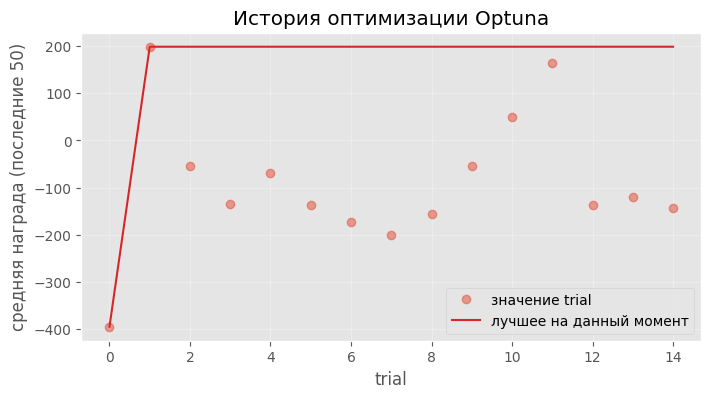

In [42]:
values = [t.value for t in study.trials if t.value is not None]
best = np.maximum.accumulate(values)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(values, "o", alpha=0.5, label="значение trial")
ax.plot(best, "-", color="tab:red", label="лучшее на данный момент")
ax.set_xlabel("trial"); ax.set_ylabel("средняя награда (последние 50)")
ax.set_title("История оптимизации Optuna")
ax.legend(); ax.grid(alpha=0.3)
plt.show()

Эпизод   20 | награда=  -93.1 | Средняя(100)=  -58.9 | ε=0.050
Эпизод   40 | награда=   95.5 | Средняя(100)=   42.3 | ε=0.050
Эпизод   60 | награда=  266.4 | Средняя(100)=   77.7 | ε=0.050
Эпизод   80 | награда=  120.3 | Средняя(100)=  105.1 | ε=0.050
Эпизод  100 | награда=  289.8 | Средняя(100)=  123.0 | ε=0.050
Эпизод  120 | награда=  192.7 | Средняя(100)=  174.1 | ε=0.050
Эпизод  140 | награда=  272.1 | Средняя(100)=  178.7 | ε=0.050
Эпизод  160 | награда=  286.0 | Средняя(100)=  193.6 | ε=0.050


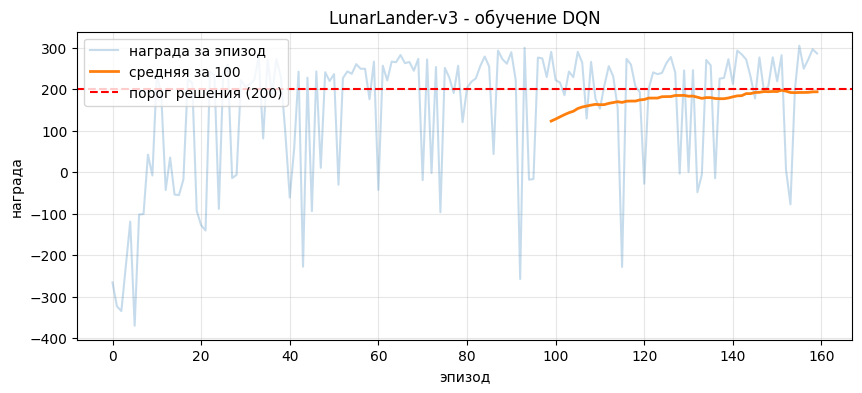

Решено на эпизоде 173 | Средняя за 100: 200.4


In [13]:
# Запускаем обучение агента с лучшими гиперпараметрами
agent, rewards = train(
    env_id="LunarLander-v3",
    n_episodes=1000,
    plot_every=20,
    live_plot=True,
    agent_kwargs=best_params,
)

In [14]:
torch.save(agent.q_net.state_dict(), "dqn_lunarlander_best.pth")

Как видим, подбор гиперпараметров позволил обучить агента за  173 эпизода против 400 при случайной инициализации параметров